In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Dataset/master_fataka_sales.csv")
df["Date"] = pd.to_datetime(df["Date"])

print(f"Total 5-Year Revenue: ₹{df['Total_Revenue'].sum():,.2f}")
df.head(3)

Total 5-Year Revenue: ₹30,868,900.00


,Transaction_ID,Date,Days_To_Diwali,Product_ID,Product_Name,Category,Unit_Price,Quantity_Sold,Total_Revenue,Data_Source
0,TX100023,2023-09-28,45,P601,Fancy Sky Shot 7-Shot,Aerial Shots,450,3,1350.0,Logbook_Year_1
1,TX100039,2023-09-28,45,P203,Flower Pots Special,Ground Novelties,350,3,1050.0,Logbook_Year_1
2,TX100009,2023-09-28,45,P401,Atom Bomb (Standard),Bombs,100,6,600.0,Logbook_Year_1


    Performs exploratory data analysis on the 5-year hybrid Fataka sales dataset,
    prints key summary statistics, performs ABC analysis, and generates visualization charts.

In [5]:
# Category Summary
category_summary = df.groupby("Category").agg(
    Total_Revenue=("Total_Revenue", "sum"),
    Total_Units=("Quantity_Sold", "sum"),
    Transactions=("Transaction_ID", "count")
).sort_values(by="Total_Revenue", ascending=False).reset_index()

display(category_summary)

,Category,Total_Revenue,Total_Units,Transactions
0,Aerial Shots,20364050.0,12768,3698
1,Ground Novelties,3795310.0,19632,5658
2,Rockets,2710540.0,10210,2919
3,Novelties,1505040.0,6554,1878
4,Sparklers,1388180.0,13837,3906
5,Bombs,1105780.0,6841,1941


C:\Users\Yash\AppData\Local\Temp\ipykernel_29560\2354542543.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=category_summary, x="Total_Revenue", y="Category", palette="viridis")


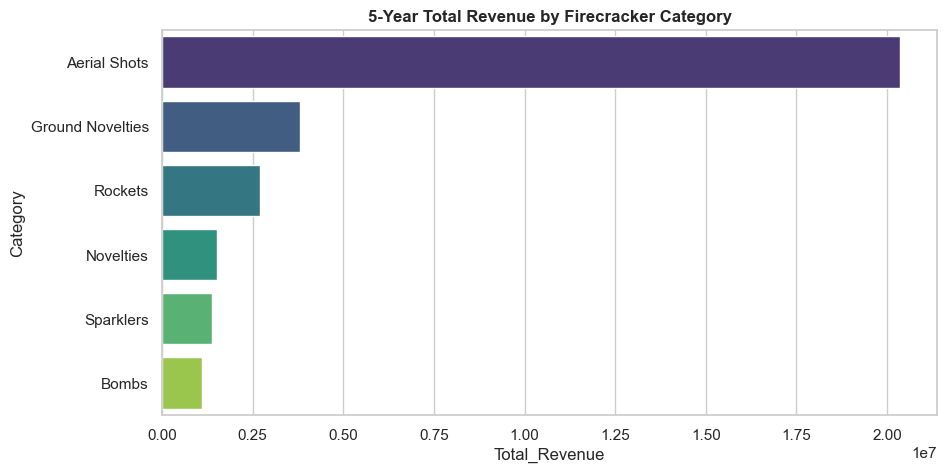

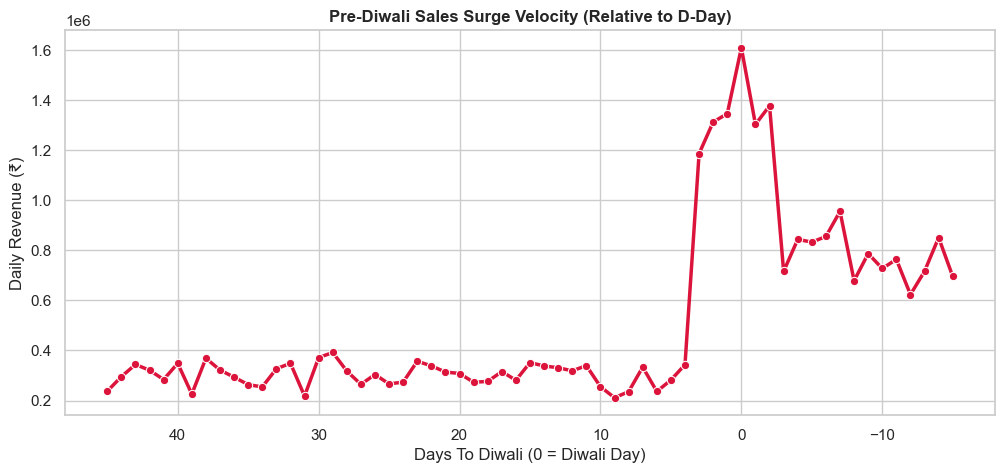

In [6]:
sns.set_theme(style="whitegrid")

# Chart 1: Revenue by Category
plt.figure(figsize=(10, 5))
sns.barplot(data=category_summary, x="Total_Revenue", y="Category", palette="viridis")
plt.title("5-Year Total Revenue by Firecracker Category", fontsize=12, fontweight="bold")
plt.show()

# Chart 2: Pre-Diwali Demand Velocity Curve
plt.figure(figsize=(12, 5))
sns.lineplot(data=df.groupby("Days_To_Diwali")["Total_Revenue"].sum().reset_index(), 
             x="Days_To_Diwali", y="Total_Revenue", marker="o", color="crimson", linewidth=2.5)
plt.title("Pre-Diwali Sales Surge Velocity (Relative to D-Day)", fontsize=12, fontweight="bold")
plt.xlabel("Days To Diwali (0 = Diwali Day)")
plt.ylabel("Daily Revenue (₹)")
plt.gca().invert_xaxis()
plt.show()